# Perhitungan Volume Kedua Lambung Perahu Katamaran

Nama : Dhea Alya Afkarina

NPM  : 25083010018

Kelas : A -Analisis Numerik

Link Github : https://github.com/dheaalyaafkarinaa-bi/Analisis_Numerik


## Rumus

Luas penampang persegi panjang: $A(x) = b(x)\,h(x)$, dengan $b$ = lebar (tampak atas) dan $h$ = tinggi (tampak samping). Volume: $V = \int_0^L A(x)\,dx$, dihampiri dengan $n$ interval sama panjang $\Delta x$.

**Trapesium:**
$$V \approx \Delta x\left[\frac{A_0 + A_n}{2} + A_1 + A_2 + \dots + A_{n-1}\right]$$

**Simpson 1/3** ($n$ genap):
$$V \approx \frac{\Delta x}{3}\Big[A_0 + 4\,(A_1 + A_3 + \dots + A_{n-1}) + 2\,(A_2 + A_4 + \dots + A_{n-2}) + A_n\Big]$$

## Skala dan Titik Pengukuran

Garis grid dinomori dari kiri, garis ke-1 adalah garis pertama di dalam bingkai grid. Titik ukur $x_0 \dots x_{16}$ berada pada garis ke-2 sampai ke-18, sehingga $n = 18 - 2 = 16$ interval. Setiap interval selebar satu kotak: $\Delta x = 0{,}45$ m dan $L = 16 \times 0{,}45 = 7{,}2$ m.

Ukuran pada gambar dibaca dalam piksel (PDF dirender 300 dpi). Garis ke-2 berada di 301,5 px dan garis ke-18 di 2012,5 px, sehingga jarak 16 kotak pada gambar adalah 1711 px.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# skala
n = 16
m_per_kotak = 0.45
px_per_kotak = (2012.5 - 301.5) / n          # jarak satu kotak pada gambar (px)
m_per_px = m_per_kotak / px_per_kotak

dx = m_per_kotak
x = np.arange(n + 1) * dx                    # posisi x0 ... x16 (m)
L = n * dx

print(f"1 kotak = {px_per_kotak:.1f} px, 1 px = {m_per_px*1000:.2f} mm")
print(f"n = {n}, dx = {dx} m, L = {L:.1f} m")

1 kotak = 106.9 px, 1 px = 4.21 mm
n = 16, dx = 0.45 m, L = 7.2 m


## Data Pengukuran

Pada setiap garis grid ($x_0$ sampai $x_{16}$) dibaca dari gambar, dalam piksel:

- **Lebar** $b$ tiap lambung (tampak atas): jarak antara tepi luar garis lambung sisi atas dan sisi bawah.
- **Tinggi** $h$ (tampak samping): jarak dari tepi atas garis dek sampai tepi bawah garis dasar lambung. Satu profil tinggi dipakai untuk kedua lambung.

Pada $x_2$ (garis grid ke-4), garis tepi lambung tertutup penopang melintang sehingga lebarnya tidak terbaca (`nan`). Nilainya diisi dengan interpolasi linear dari $x_1$ dan $x_3$.

In [4]:
# data pengukuran (piksel), urut x0 ... x16
lebar1_px = np.array([188, 206, np.nan, 226, 230, 230, 230, 230, 230, 230, 230, 230, 226, 216, 200, 174, 145])
lebar2_px = np.array([189, 207, np.nan, 225, 230, 230, 230, 230, 230, 230, 230, 227, 225, 216, 198, 175, 143])
tinggi_px = np.array([207, 244, 274, 283, 283, 283, 283, 283, 283, 283, 281, 281, 281, 281, 281, 281, 281])

def isi_kosong(a):
    idx = np.arange(len(a))
    ada = ~np.isnan(a)
    return np.interp(idx, idx[ada], a[ada])

b1 = isi_kosong(lebar1_px) * m_per_px        # lebar lambung 1
b2 = isi_kosong(lebar2_px) * m_per_px        # lebar lambung 2
h = tinggi_px * m_per_px                     # tinggi lambung

Gambar berikut menunjukkan bagian lambung yang dihitung (garis grid ke-2 sampai ke-18, titik $x_0 \dots x_{16}$), direkonstruksi dari data ukur.

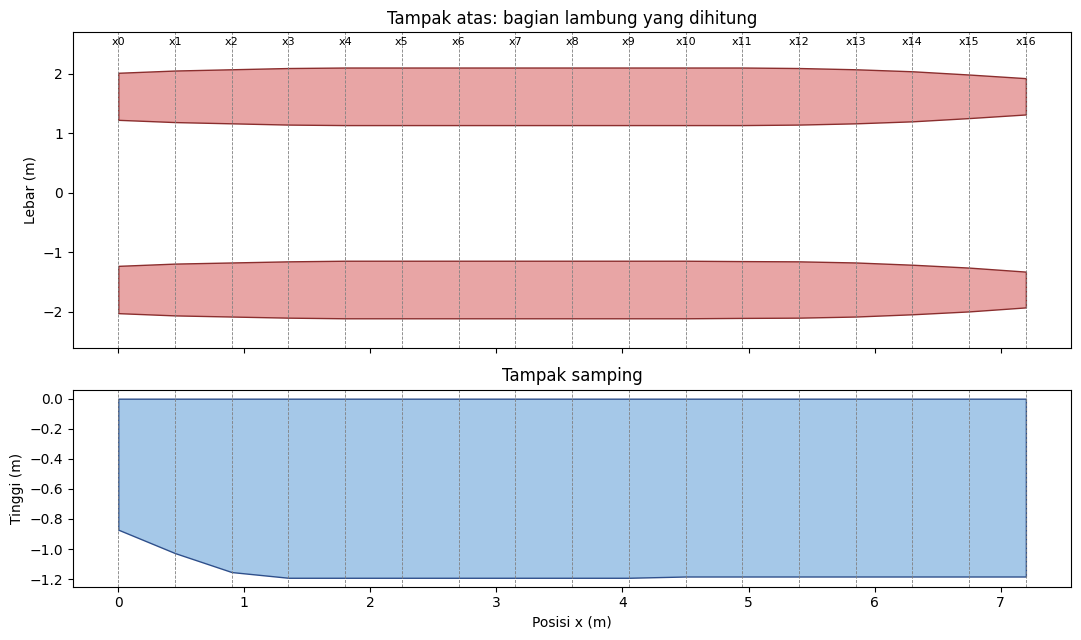

In [5]:
jarak_sumbu_px = 386                         # jarak sumbu tiap lambung ke sumbu simetri (px)
pusat = jarak_sumbu_px * m_per_px

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                             gridspec_kw={"height_ratios": [1.6, 1]})
a1.fill_between(x, pusat - b1 / 2, pusat + b1 / 2, color="#e8a5a5", ec="#8b2e2e")
a1.fill_between(x, -pusat - b2 / 2, -pusat + b2 / 2, color="#e8a5a5", ec="#8b2e2e")
a1.set_title("Tampak atas: bagian lambung yang dihitung")
a1.set_ylabel("Lebar (m)")
a1.set_ylim(-2.6, 2.7)
a2.fill_between(x, 0, -h, color="#a5c8e8", ec="#2e4f8b")
a2.set_title("Tampak samping")
a2.set_ylabel("Tinggi (m)")
a2.set_xlabel("Posisi x (m)")
for i, xi in enumerate(x):
    a1.axvline(xi, color="gray", lw=0.6, ls="--")
    a2.axvline(xi, color="gray", lw=0.6, ls="--")
    a1.text(xi, 2.45, f"x{i}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

## Luas Penampang dan Volume

$A_i = b_i \times h_i$ pada setiap titik, lalu volume dihitung dengan kedua metode.

In [6]:
A1 = b1 * h
A2 = b2 * h

print(pd.DataFrame({"x (m)": x, "b1 (m)": b1, "b2 (m)": b2, "h (m)": h,
                    "A1 (m2)": A1, "A2 (m2)": A2},
                   index=[f"x{i}" for i in range(n + 1)]).round(4))

def trapesium(A, dx):
    return dx * ((A[0] + A[-1]) / 2 + A[1:-1].sum())

def simpson(A, dx):
    return dx / 3 * (A[0] + 4 * A[1:-1:2].sum() + 2 * A[2:-1:2].sum() + A[-1])

print()
print(f"{'Metode':<12}{'Lambung 1':>12}{'Lambung 2':>12}{'Kedua lambung':>16}   (m3)")
for nama, f in [("Trapesium", trapesium), ("Simpson 1/3", simpson)]:
    v1, v2 = f(A1, dx), f(A2, dx)
    print(f"{nama:<12}{v1:>12.4f}{v2:>12.4f}{v1 + v2:>16.4f}")

selisih = (simpson(A1, dx) + simpson(A2, dx)) - (trapesium(A1, dx) + trapesium(A2, dx))
print(f"\nSelisih Simpson - trapesium (kedua lambung) = {selisih:.4f} m3")

     x (m)  b1 (m)  b2 (m)   h (m)  A1 (m2)  A2 (m2)
x0    0.00  0.7911  0.7953  0.8711   0.6891   0.6928
x1    0.45  0.8669  0.8711  1.0268   0.8901   0.8944
x2    0.90  0.9089  0.9089  1.1530   1.0480   1.0480
x3    1.35  0.9510  0.9468  1.1909   1.1326   1.1275
x4    1.80  0.9679  0.9679  1.1909   1.1526   1.1526
x5    2.25  0.9679  0.9679  1.1909   1.1526   1.1526
x6    2.70  0.9679  0.9679  1.1909   1.1526   1.1526
x7    3.15  0.9679  0.9679  1.1909   1.1526   1.1526
x8    3.60  0.9679  0.9679  1.1909   1.1526   1.1526
x9    4.05  0.9679  0.9679  1.1909   1.1526   1.1526
x10   4.50  0.9679  0.9679  1.1825   1.1445   1.1445
x11   4.95  0.9679  0.9552  1.1825   1.1445   1.1295
x12   5.40  0.9510  0.9468  1.1825   1.1246   1.1196
x13   5.85  0.9089  0.9089  1.1825   1.0748   1.0748
x14   6.30  0.8416  0.8332  1.1825   0.9952   0.9852
x15   6.75  0.7322  0.7364  1.1825   0.8658   0.8708
x16   7.20  0.6102  0.6018  1.1825   0.7215   0.7116

Metode         Lambung 1   Lambung 2   Kedua 

## 6. Kesimpulan

Volume bagian utama kedua lambung (garis grid ke-2 sampai ke-18, tanpa *reserve buoyancy*):

| Metode | Lambung 1 | Lambung 2 | Kedua lambung |
|---|---|---|---|
| Trapesium | 7,6684 m³ | 7,6554 m³ | 15,3238 m³ |
| Simpson 1/3 | 7,6819 m³ | 7,6701 m³ | **15,3520 m³** |

Kedua metode berselisih 0,0282 m³ (0,18 %).